# 🏎️ Predicting the Austin F1 podium with machine learning
**Day 4 of 30 Days to MLE · [@buildwithakshita](https://www.instagram.com/buildwithakshita/)**

Can a model I built on Day 4 of learning ML predict the **2026 United States Grand Prix** podium (COTA, Oct 25)?

| | |
|---|---|
| **Question** | Will this driver finish on the podium? (yes / no) |
| **Model** | Random forest classifier (and logistic regression for comparison) |
| **History data** | [F1DB](https://github.com/f1db/f1db): every F1 result ever, open source |
| **Race-weekend data** | [FastF1](https://docs.fastf1.dev): live practice + qualifying times |
| **Tested on** | all 17 races of 2026, predicting each one using only data from before it |

**Three modes, each one smarter than the last:**
1. **Pre-weekend:** recent form, points, car strength, track history
2. **After practice (Fri/Sat):** + practice lap pace
3. **After qualifying (Sat night):** + starting grid

> **On Kaggle:** Settings → turn **Internet on** before running.

In [1]:
!pip -q install fastf1
import os, io, zipfile, urllib.request, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss
warnings.filterwarnings("ignore")

YEAR, GP = 2026, "united-states"       # change these to predict another race
FASTF1_NAME = "United States"          # name FastF1 uses for the same race

D = "f1db/"
if not os.path.exists(D + "f1db-races.csv"):
    url = "https://github.com/f1db/f1db/releases/latest/download/f1db-csv.zip"
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extractall(D)
races   = pd.read_csv(D + "f1db-races.csv")
results = pd.read_csv(D + "f1db-races-race-results.csv", low_memory=False)
drivers = pd.read_csv(D + "f1db-drivers.csv").set_index("id")
teams   = pd.read_csv(D + "f1db-constructors.csv").set_index("id")
fp = pd.concat([pd.read_csv(D + f"f1db-races-free-practice-{n}-results.csv", low_memory=False) for n in (1, 2, 3)])
latest = races[races.id == results.raceId.max()].iloc[0]
print(f"Data up to: {latest.officialName} ({latest.date})")

Data up to: Formula 1 Singapore Airlines Singapore Grand Prix 2026 (2026-10-11)


### 🎨 Brand style
Every chart below uses the same palette and fonts: forest background, cream text, rust for the highlights.

In [2]:
import matplotlib as mpl
from matplotlib import font_manager as fm
import plotly.io as pio, plotly.express as px, plotly.graph_objects as go

FOREST, OLIVE, CREAM, TAN, RUST = "#273518", "#5F6C37", "#FEFADF", "#DDA05E", "#BC6C25"
MUTED = "#465237"   # olive-forest for gridlines and hidden bars

# fonts: Playfair Display (titles) + Montserrat (everything else)
FONT_URLS = {
    "Montserrat": "https://cdn.jsdelivr.net/npm/@expo-google-fonts/montserrat@0.4.2/600SemiBold/Montserrat_600SemiBold.ttf",
    "Montserrat Bold": "https://cdn.jsdelivr.net/npm/@expo-google-fonts/montserrat@0.4.2/700Bold/Montserrat_700Bold.ttf",
    "Playfair": "https://cdn.jsdelivr.net/npm/@expo-google-fonts/playfair-display@0.4.2/400Regular/PlayfairDisplay_400Regular.ttf",
}
FONTS = {}
os.makedirs("fonts", exist_ok=True)
for name, url in FONT_URLS.items():
    path = "fonts/" + url.split("/")[-1]
    try:
        if not os.path.exists(path): urllib.request.urlretrieve(url, path)
        fm.fontManager.addfont(path); FONTS[name] = fm.FontProperties(fname=path)
    except Exception:
        FONTS[name] = fm.FontProperties(family="DejaVu Sans")   # fallback if offline
BODY = FONTS["Montserrat"].get_name()

mpl.rcParams.update({
    "figure.facecolor": FOREST, "axes.facecolor": FOREST, "savefig.facecolor": FOREST,
    "text.color": CREAM, "axes.labelcolor": CREAM, "xtick.color": CREAM, "ytick.color": CREAM,
    "axes.edgecolor": FOREST, "axes.grid": False, "font.family": BODY, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False, "axes.spines.bottom": False,
})

def brand_title(ax, title, subtitle=None):
    ax.set_title(title, loc="left", pad=28 if subtitle else 14, fontproperties=FONTS["Playfair"], fontsize=20, color=TAN)
    if subtitle: ax.text(0, 1.02, subtitle.upper(), transform=ax.transAxes, fontproperties=FONTS["Montserrat"], fontsize=9, color=CREAM)

pio.templates["brand"] = go.layout.Template(layout=dict(
    paper_bgcolor=FOREST, plot_bgcolor=FOREST,
    font=dict(family="Montserrat, Arial", color=CREAM, size=13),
    title=dict(font=dict(family="Playfair Display, Georgia, serif", color=TAN, size=24), x=0.02),
    colorway=[RUST, TAN, OLIVE, CREAM],
    xaxis=dict(gridcolor=MUTED, zeroline=False, linecolor=MUTED), yaxis=dict(gridcolor=FOREST, zeroline=False),
    legend=dict(bgcolor="rgba(0,0,0,0)"), margin=dict(l=20, r=40, t=80, b=40)))
pio.templates.default = "brand"
print("brand style ready ✓")

brand style ready ✓


## 1. Clean the results
- **Target (y):** `podium` = 1 if the driver finished top 3
- **Blank points = 0** (F1DB leaves points empty for non-scorers; averaging blanks would inflate midfield drivers).
- **DNF / DSQ / DNS removed from the inputs.** A crash or disqualification says little about pace, so they don't count as "20th place" when measuring form. (They still count as "no podium" when testing, so results stay honest.)
- Keep 2021 onwards: older F1 is a different sport.

In [3]:
rr = results[results.year >= 2021].merge(races[["id", "grandPrixId", "date"]], left_on="raceId", right_on="id")
rr["points"] = rr.points.fillna(0)                   # F1DB leaves points blank when a driver scores none
rr["out"] = rr.positionNumber.isna()                 # DNF, DSQ, DNS, NC
rr["podium"] = (rr.positionNumber <= 3).astype(int)
order = rr[["raceId", "date"]].drop_duplicates().sort_values("date").reset_index(drop=True)
order["idx"] = range(len(order))
rr = rr.merge(order[["raceId", "idx"]], on="raceId").sort_values(["idx", "positionDisplayOrder"])

# practice pace: best lap across FP1-3 as % slower than the fastest car that weekend
fp = fp[fp.year >= 2021].dropna(subset=["timeMillis"])
fp = fp.groupby(["raceId", "driverId"]).timeMillis.min().reset_index()
fp["fp_gap"] = fp.groupby("raceId").timeMillis.transform(lambda s: (s / s.min() - 1) * 100)
print(rr.out.sum(), "non-finishes removed from inputs out of", len(rr), "results")

341 non-finishes removed from inputs out of 2653 results


## 2. Features (x)
Built for every driver **before** every race, using only races that already happened (no peeking into the future = no data leakage).

| Feature | Meaning |
|---|---|
| `form` | average finish in their last 3 *classified* races |
| `points` | average points in their last 5 classified races |
| `car` | team points per race over the last 5 races (how fast the car is) |
| `track` | average finish at this Grand Prix, **shrunk** toward current form when they've raced here only a few times |
| `fp_gap` | *(weekend mode)* practice pace, % off the fastest |
| `grid` | *(weekend mode)* starting position |

**Why shrink `track`?** A driver with one bad result here (e.g. a rookie) shouldn't be judged on one race. With *n* visits:
`track = (n × track_avg + 2 × form) / (n + 2)`. One visit → mostly current form. Five visits → mostly track record.

In [4]:
K = 2   # shrinkage strength

def build_features(past, entrants, gp):
    last_races = past.idx.drop_duplicates().nlargest(5)
    last5 = past[past.idx.isin(last_races)]
    car = last5.groupby("constructorId").points.sum() / max(len(last_races), 1)
    rows = []
    for _, d in entrants.iterrows():
        mine = past[(past.driverId == d.driverId) & ~past.out]
        form = mine.tail(3).positionNumber.mean()
        form = 15 if np.isnan(form) else form
        here = mine[mine.grandPrixId == gp]
        n = len(here)
        track = (here.positionNumber.sum() + K * form) / (n + K)
        rows.append(dict(driverId=d.driverId, team=d.constructorId, form=form,
                         points=mine.tail(5).points.mean() if len(mine) else 0,
                         car=car.get(d.constructorId, 0), track=track, track_visits=n))
    return pd.DataFrame(rows)

parts = []
for _, r in order.iterrows():
    if r.idx < 5: continue
    cur = rr[rr.raceId == r.raceId]
    f = build_features(rr[rr.idx < r.idx], cur, cur.grandPrixId.iloc[0])
    f = f.merge(cur[["driverId", "podium", "out", "gridPositionNumber", "positionNumber"]], on="driverId")
    f["raceId"], f["idx"], f["year"] = r.raceId, r.idx, cur.year.iloc[0]
    parts.append(f)
data = pd.concat(parts).merge(fp[["raceId", "driverId", "fp_gap"]], on=["raceId", "driverId"], how="left")
data["fp_gap"] = data.fp_gap.fillna(data.groupby("raceId").fp_gap.transform("max"))
data["grid"] = data.gridPositionNumber.fillna(22)
data = data[data.year >= 2022].fillna({"points": 0})
print(data.shape)
data.head()

(2213, 16)


,driverId,team,form,points,car,track,track_visits,podium,out,gridPositionNumber,positionNumber,raceId,idx,year,fp_gap,grid
340,charles-leclerc,ferrari,8.333333,6.2,14.4,7.555556,1,1,False,1.0,1.0,1058,22,2022,0.094631,1.0
341,carlos-sainz-jr,ferrari,6.000000,8.2,14.4,6.666667,1,1,False,3.0,2.0,1058,22,2022,0.635225,3.0
342,lewis-hamilton,mercedes,1.333333,22.4,30.0,1.222222,1,1,False,5.0,3.0,1058,22,2022,1.288940,5.0
343,george-russell,mercedes,15.333333,0.0,30.0,14.888889,1,0,False,9.0,4.0,1058,22,2022,0.645014,9.0
344,kevin-magnussen,haas,15.000000,0.0,0.0,15.000000,0,0,False,7.0,5.0,1058,22,2022,1.356378,7.0


## 3. Test honestly: predict every 2026 race using only the past
For each 2026 race: train on everything before it → predict → compare with what really happened.

**Metrics** (why not plain accuracy? Only 3 of 22 drivers podium, so a model saying "no" to everyone is 86% "accurate"):
- **Podium hits:** of the model's top 3, how many really finished top 3 (random guessing ≈ 14%)
- **Winner in top 3:** was the race winner one of its 3 picks?
- **AUC:** how well it ranks podium drivers above the rest (0.5 = coin flip, 1 = perfect)
- **Brier:** are the percentages trustworthy? (lower = better)

In [5]:
BASE = ["form", "points", "car", "track"]
MODES = {"1. pre-weekend": BASE, "2. + practice": BASE + ["fp_gap"], "3. + grid": BASE + ["fp_gap", "grid"]}
make_rf = lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=20, random_state=0)
make_lr = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

def backtest(features, make_model, year=2026):
    preds = []
    for i in sorted(data[data.year == year].idx.unique()):
        train = data[(data.idx < i) & ~data.out]
        test = data[data.idx == i]
        model = make_model().fit(train[features], train.podium)
        preds.append(test.assign(p=model.predict_proba(test[features])[:, 1]))
    return pd.concat(preds)

def score(t):
    hits = winner = 0
    for _, g in t.groupby("raceId"):
        top3 = set(g.nlargest(3, "p").driverId)
        hits += len(top3 & set(g[g.podium == 1].driverId))
        winner += int(g[g.positionNumber == 1].driverId.isin(top3).any())
    n = t.raceId.nunique()
    return {"podium hits": f"{hits}/{3*n} ({hits/(3*n):.0%})", "winner in top 3": f"{winner}/{n}",
            "AUC": round(roc_auc_score(t.podium, t.p), 3),
            "Brier": round(brier_score_loss(t.podium, t.p), 3) if t.p.between(0, 1).all() else "–"}

table, tests = {}, {}
for name, feats in MODES.items():
    tests[name] = backtest(feats, make_rf)
    table[name + " (random forest)"] = score(tests[name])
table["1. pre-weekend (logistic regression)"] = score(backtest(BASE, make_lr))
t = data[data.year == 2026]
table["rule: most points lately"] = score(t.assign(p=t.points))
table["rule: fastest in practice"] = score(t.assign(p=-t.fp_gap))
table["rule: top 3 on the grid"] = score(t.assign(p=-t.grid))
results_table = pd.DataFrame(table).T
results_table

,podium hits,winner in top 3,AUC,Brier
1. pre-weekend (random forest),26/51 (51%),11/17,0.902,0.083
2. + practice (random forest),28/51 (55%),13/17,0.916,0.077
3. + grid (random forest),34/51 (67%),15/17,0.946,0.064
1. pre-weekend (logistic regression),20/51 (39%),11/17,0.888,0.091
rule: most points lately,22/51 (43%),10/17,0.884,–
rule: fastest in practice,31/51 (61%),13/17,0.917,–
rule: top 3 on the grid,32/51 (63%),16/17,0.936,–


findfont: Failed to find font weight normal for Montserrat, now using 600.


findfont: Failed to find font weight normal for Montserrat, now using 600.


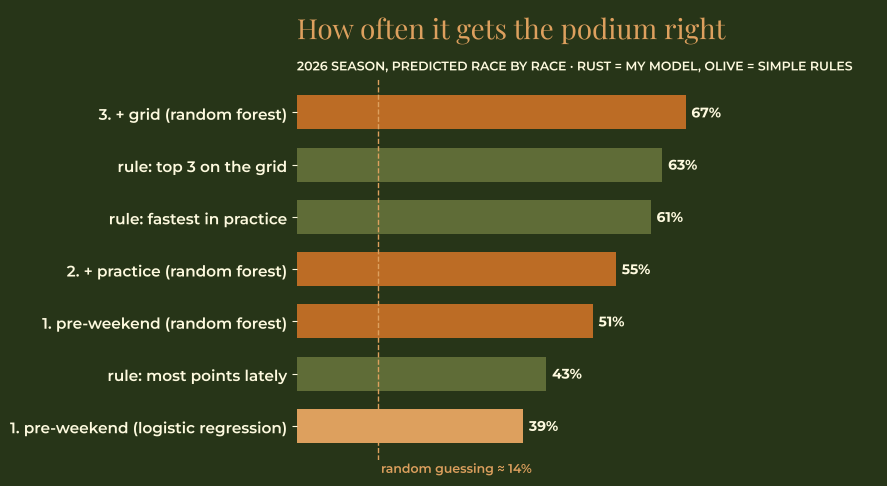

In [6]:
# podium hit rate, as a chart
hit = results_table["podium hits"].str.extract(r"\((\d+)%\)")[0].astype(int)
fig, ax = plt.subplots(figsize=(9, 5))
order_ = hit.sort_values()
colors = [RUST if "random forest" in n else (TAN if "logistic" in n else OLIVE) for n in order_.index]
ax.barh(order_.index, order_.values, color=colors, height=0.65)
for y, v in enumerate(order_.values): ax.text(v + 1, y, f"{v}%", va="center", fontproperties=FONTS["Montserrat Bold"], color=CREAM)
ax.axvline(14, color=TAN, ls="--", lw=1); ax.text(14.5, -0.9, "random guessing ≈ 14%", color=TAN, fontsize=9)
ax.set_xlim(0, 100); ax.set_xticks([])
brand_title(ax, "How often it gets the podium right", "2026 season, predicted race by race · rust = my model, olive = simple rules")
plt.tight_layout(); plt.show()

### Are the percentages honest? (calibration)
If the model says 40%, those drivers should podium about 40% of the time.

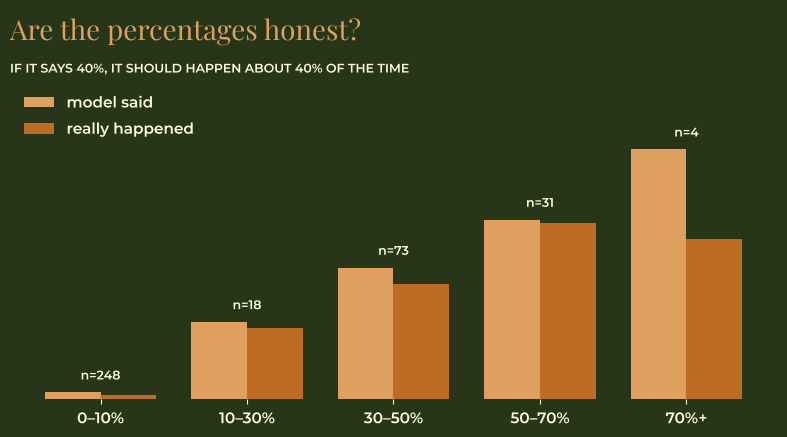

,drivers,model_said,really_happened
bucket,,,
"(-0.001, 0.1]",248,0.02,0.01
"(0.1, 0.3]",18,0.24,0.22
"(0.3, 0.5]",73,0.41,0.36
"(0.5, 0.7]",31,0.56,0.55
"(0.7, 1.0]",4,0.78,0.50


In [7]:
cal = tests["1. pre-weekend"].assign(bucket=lambda d: pd.cut(d.p, [0, .1, .3, .5, .7, 1], include_lowest=True))
cal_table = cal.groupby("bucket").agg(drivers=("p", "size"), model_said=("p", "mean"), really_happened=("podium", "mean")).round(2)
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(cal_table)); w = 0.38
ax.bar(x - w/2, cal_table.model_said, w, color=TAN, label="model said")
ax.bar(x + w/2, cal_table.really_happened, w, color=RUST, label="really happened")
ax.set_xticks(x, ["0–10%", "10–30%", "30–50%", "50–70%", "70%+"]); ax.set_yticks([])
for i, (a, b, n) in enumerate(zip(cal_table.model_said, cal_table.really_happened, cal_table.drivers)):
    ax.text(i, max(a, b) + 0.04, f"n={n}", ha="center", fontsize=9, color=CREAM)
ax.legend(frameon=False, loc="upper left"); ax.set_ylim(0, 1)
brand_title(ax, "Are the percentages honest?", "if it says 40%, it should happen about 40% of the time")
plt.tight_layout(); plt.show()
cal_table

**Result:** low and mid percentages are honest, but when the model says 70%+, it's overconfident (few examples, and F1 is chaotic). Read high numbers as *"favourite"*, not as a guarantee.

## 4. 🏁 Pre-weekend Austin prediction

,driver,team_name,form,points,car,track,track_visits,p
2,Antonelli,Mercedes,3.3,18.6,29.6,6.6,1,66%
0,Verstappen,Red Bull,1.3,20.2,27.0,1.4,5,64%
8,Russell,Mercedes,10.0,11.0,29.6,8.0,5,59%
1,Leclerc,Ferrari,3.3,12.8,18.6,2.9,4,51%
9,Hadjar,Red Bull,6.0,8.4,27.0,9.3,1,39%
3,Norris,McLaren,5.3,13.2,14.6,4.7,5,33%
5,Hamilton,Ferrari,5.0,10.2,18.6,3.6,3,30%
4,Piastri,McLaren,8.0,6.4,14.6,6.5,2,22%
13,Sainz Jr.,Williams,13.7,0.2,0.2,7.9,3,3%
16,Pérez,Cadillac,16.7,0.0,0.0,8.6,4,3%


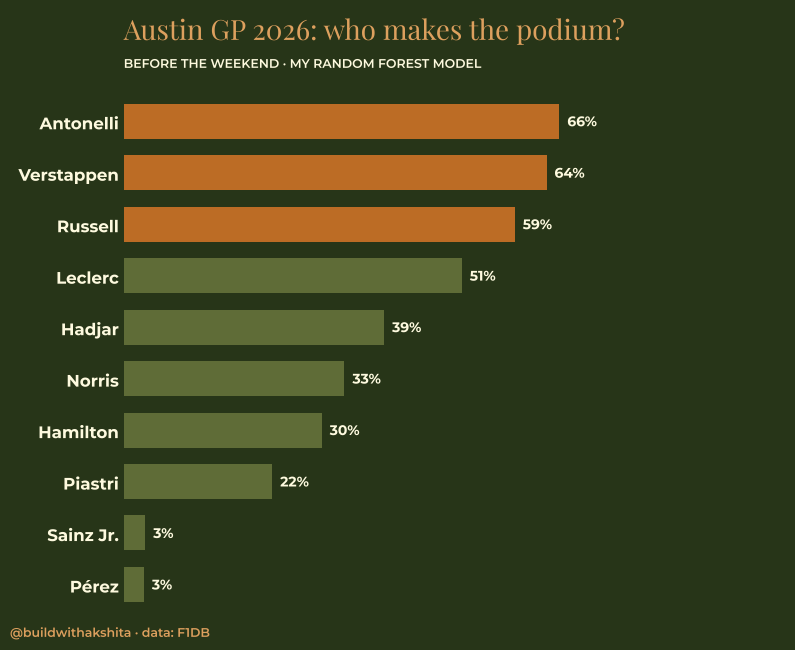

In [8]:
race_id = races[(races.year == YEAR) & (races.grandPrixId == GP)].id.iloc[0]
last = rr.idx.max()
lineup = rr[rr.idx == last][["driverId", "constructorId"]]
austin = build_features(rr, lineup, GP)
austin["driver"] = austin.driverId.map(drivers.lastName)
austin["team_name"] = austin.team.map(teams.name)

train = data[~data.out]
models = {name: make_rf().fit(train[f], train.podium) for name, f in MODES.items()}
austin["p"] = models["1. pre-weekend"].predict_proba(austin[BASE])[:, 1]

def chart(df, title, subtitle="podium chance · my random forest model"):
    top = df.nlargest(10, "p").iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 6.5))
    ax.barh(top.driver, top.p, color=[RUST if i >= 7 else OLIVE for i in range(len(top))], height=0.68)
    for y, v in enumerate(top.p): ax.text(v + 0.012, y, f"{v:.0%}", va="center", fontproperties=FONTS["Montserrat Bold"], color=CREAM)
    for lbl in ax.get_yticklabels(): lbl.set_fontproperties(FONTS["Montserrat Bold"]); lbl.set_fontsize(12)
    ax.tick_params(length=0); ax.set_xlim(0, 1); ax.set_xticks([])
    brand_title(ax, title, subtitle)
    fig.text(0.01, 0.01, "@buildwithakshita · data: F1DB", color=TAN, fontsize=9)
    plt.tight_layout(); plt.show()

display(austin.sort_values("p", ascending=False)[["driver", "team_name", "form", "points", "car", "track", "track_visits", "p"]]
        .head(10).style.format({"p": "{:.0%}", "form": "{:.1f}", "points": "{:.1f}", "car": "{:.1f}", "track": "{:.1f}"}))
chart(austin, "Austin GP 2026: who makes the podium?", "before the weekend · my random forest model")

## 5. What did it learn?
Random forests don't have weights, but we can see which features they rely on most.

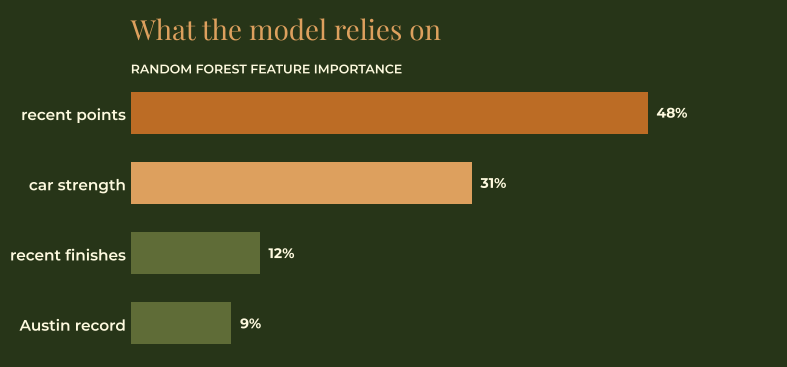

In [9]:
imp = pd.Series(models["1. pre-weekend"].feature_importances_, index=BASE).sort_values()
names = {"points": "recent points", "car": "car strength", "track": "Austin record", "form": "recent finishes"}
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh([names[i] for i in imp.index], imp.values, color=[OLIVE, OLIVE, TAN, RUST], height=0.6)
for y, v in enumerate(imp.values): ax.text(v + 0.008, y, f"{v:.0%}", va="center", fontproperties=FONTS["Montserrat Bold"], color=CREAM)
ax.tick_params(length=0); ax.set_xticks([]); ax.set_xlim(0, imp.max() * 1.25)
brand_title(ax, "What the model relies on", "random forest feature importance")
plt.tight_layout(); plt.show()

## 6. 🏁 Race-weekend mode (run this at the track!)
FastF1 pulls practice and qualifying times **within hours** of each session (F1DB only updates after the weekend).

- **After FP1/FP2 (Fri)** or **FP3 (Sat morning):** uses practice pace
- **After qualifying (Sat night):** uses practice pace + starting grid

If FastF1 can't load a session yet, fill in `MANUAL_GRID` by hand (driver code → grid position).

In [10]:
import fastf1, logging
logging.getLogger("fastf1").setLevel(logging.ERROR)
os.makedirs("ff1cache", exist_ok=True); fastf1.Cache.enable_cache("ff1cache")
code_to_id = {drivers.loc[d, "abbreviation"]: d for d in austin.driverId}

def practice_pace():
    best = {}
    for s in ["FP1", "FP2", "FP3"]:
        try:
            ses = fastf1.get_session(YEAR, FASTF1_NAME, s); ses.load(laps=True, telemetry=False, weather=False, messages=False)
            for code, t in ses.laps.groupby("Driver").LapTime.min().dropna().items():
                best[code] = min(best.get(code, t), t)
            print(f"loaded {s}")
        except Exception as e:
            print(f"{s} not available yet")
    if not best: return None
    s = pd.Series({k: v.total_seconds() for k, v in best.items()})
    return ((s / s.min() - 1) * 100).rename(index=code_to_id)

def quali_grid():
    try:
        ses = fastf1.get_session(YEAR, FASTF1_NAME, "Q"); ses.load(laps=False, telemetry=False, weather=False, messages=False)
        res = ses.results.dropna(subset=["Position"])
        if res.empty: raise ValueError
        print("loaded qualifying")
        return res.set_index("Abbreviation").Position.rename(index=code_to_id)
    except Exception:
        print("qualifying not available yet"); return None

MANUAL_GRID = {}   # e.g. {"VER": 1, "ANT": 2, "RUS": 3, ...}  (use the official grid if there are penalties)

pace, grid = practice_pace(), quali_grid()
if MANUAL_GRID: grid = pd.Series(MANUAL_GRID).rename(index=code_to_id)

weekend = austin.copy()
if pace is not None:
    weekend["fp_gap"] = weekend.driverId.map(pace).fillna(pace.max())
    mode = "2. + practice"
    if grid is not None:
        weekend["grid"] = weekend.driverId.map(grid).fillna(22)
        mode = "3. + grid"
    weekend["p"] = models[mode].predict_proba(weekend[MODES[mode]])[:, 1]
    print("Using model:", mode)
    display(weekend.sort_values("p", ascending=False)[["driver", "team_name", "p"] + MODES[mode][4:]].head(10).style.format({"p": "{:.0%}"}))
    chart(weekend, "Austin GP 2026: who makes the podium?", f"{mode[3:]} · my random forest model")
else:
    print("No weekend data yet: the pre-weekend prediction above is the latest.")

FP1 not available yet


FP2 not available yet


FP3 not available yet


qualifying not available yet
No weekend data yet: the pre-weekend prediction above is the latest.


## 7. ✨ Animations
Hit ▶ on each chart.

In [11]:
# 1) Championship race, round by round
s26 = rr[rr.year == YEAR].copy()
s26["driver"] = s26.driverId.map(drivers.lastName); s26["team_name"] = s26.constructorId.map(teams.name)
s26["gp"] = s26.grandPrixId.str.replace("-", " ").str.title()
cum = (s26.sort_values("idx").assign(total=lambda d: d.groupby("driverId").points.cumsum()))
frames = cum.groupby("driverId").apply(lambda d: d.set_index("round")).reset_index(level=0, drop=True).reset_index()
top = cum.groupby("driverId").total.max().nlargest(10).index
frames = frames[frames.driverId.isin(top)].copy()
frames["status"] = np.where(frames.groupby("round").total.rank(ascending=False, method="first") <= 3, "top 3", "chasing")
fig = px.bar(frames, x="total", y="driver", color="status", animation_frame="round", orientation="h",
             range_x=[0, frames.total.max() * 1.12], text="total", hover_data=["team_name", "gp"],
             color_discrete_map={"top 3": RUST, "chasing": OLIVE}, category_orders={"status": ["top 3", "chasing"]},
             title=f"{YEAR} title fight, race by race")
fig.update_traces(textposition="outside", textfont=dict(color=CREAM))
fig.update_layout(yaxis=dict(categoryorder="total ascending", title=""), xaxis=dict(title="points", showgrid=False, showticklabels=False),
                  legend_title="", height=600)
fig.layout.updatemenus[0].buttons[0].args[1]["frame"]["duration"] = 600
fig.show()

In [12]:
# 2) How my model's podium picks changed through the season (from the honest backtest)
bt = tests["1. pre-weekend"].copy()
bt["driver"] = bt.driverId.map(drivers.lastName)
bt["gp"] = bt.raceId.map(races.set_index("id").grandPrixId).str.replace("-", " ").str.title()
bt["round"] = bt.raceId.map(races.set_index("id")["round"])
bt["result"] = np.where(bt.podium == 1, "made the podium", "didn't")
keep = bt.groupby("driverId").p.max().nlargest(10).index
bt = bt[bt.driverId.isin(keep)].sort_values("round")
fig = px.scatter(bt, x="p", y="driver", color="result", size=bt.p * 40 + 5, animation_frame="round",
                 hover_name="gp", range_x=[0, 1], color_discrete_map={"made the podium": "#BC6C25", "didn't": "#5F6C37"},
                 title="My model's podium chance before each 2026 race vs what happened")
fig.update_layout(xaxis=dict(tickformat=".0%", title="predicted podium chance"), yaxis_title="", legend_title="", height=600)
fig.show()

In [13]:
# 3) The Austin prediction, revealed
a = austin.nlargest(10, "p").iloc[::-1]
fig = go.Figure(go.Bar(x=[0]*len(a), y=a.driver, orientation="h", marker_color=[RUST if i >= 7 else OLIVE for i in range(len(a))]))
fig.frames = [go.Frame(data=[go.Bar(x=a.p * k / 20, text=[f"{v*k/20:.0%}" for v in a.p], textposition="outside", textfont=dict(color=CREAM))]) for k in range(1, 21)]
fig.update_layout(title="Austin GP: who makes the podium?", xaxis=dict(range=[0, 1], showticklabels=False, showgrid=False), height=540,
                  updatemenus=[dict(type="buttons", showactive=False, x=0, y=1.12,
                                    buttons=[dict(label="▶ Reveal", method="animate", args=[None, dict(frame=dict(duration=60), fromcurrent=True)])])])
fig.show()

## Notes
- **Data:** [F1DB](https://github.com/f1db/f1db) (CC BY 4.0) and [FastF1](https://github.com/theOehrly/Fast-F1)
- **What didn't help** (tested): past qualifying, sprint results, championship rank, team reliability, overtaking, teammate comparison, circuit type, more complex models. Before the weekend, the ceiling is ~50%: most of what matters only becomes known during the weekend.
- **Next:** compare with the real result on Sunday 🏁

Follow along: [@buildwithakshita](https://www.instagram.com/buildwithakshita/) · ML basics cheat sheet: [buildwithakshita.github.io/ml-resources/day-3](https://buildwithakshita.github.io/ml-resources/day-3/)